# YOLO11n and RT-DETR-L Training and Evaluation

Train both models on all eight combinations of horizontal flip, rotation, and mosaic settings (16 total runs). Training/validation plots are enabled. Runs use the configured Platform project.

## Section 1: Install

In [1]:
!pip install -q -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 52.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 9.9 MB/s eta 0:00:00


## Section 2: Imports

In [2]:
import os
import asyncio
from concurrent.futures import ThreadPoolExecutor
import itertools
import pandas as pd
from IPython.display import display
from google.colab import userdata, files
from ultralytics import YOLO, RTDETR


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## Section 3: API Key

In [3]:
# Add ULTRALYTICS_API_KEY to Colab Secrets and grant notebook access.
os.environ['ULTRALYTICS_API_KEY'] = userdata.get('ULTRALYTICS_API_KEY')
assert os.environ.get('ULTRALYTICS_API_KEY'), 'Add ULTRALYTICS_API_KEY to Colab Secrets first.'

## Prepare the Platform NDJSON Export



In [4]:
uploaded = files.upload()
ndjson_files = [name for name in uploaded if name.lower().endswith('.ndjson')]
assert len(ndjson_files) == 1, f'Upload exactly one .ndjson file; found {len(ndjson_files)}.'
NDJSON_PATH = os.path.abspath(ndjson_files[0])

from ultralytics.data.converter import convert_ndjson_to_yolo

def _convert_ndjson_in_worker():
    return asyncio.run(
        convert_ndjson_to_yolo(NDJSON_PATH, output_path='/content/converted_datasets')
    )

with ThreadPoolExecutor(max_workers=1) as executor:
    DATA = str(executor.submit(_convert_ndjson_in_worker).result())

print(f'Converted dataset YAML: {DATA}')


Saving isy5002-g14-dataset.ndjson to isy5002-g14-dataset.ndjson
Converting isy5002-g14-dataset.ndjson fraction=1.0 → /content/converted_datasets/isy5002-g14-dataset-e1fa4d7c using 2652 train, 332 val, 331 test images: 100% ━━━━━━━━━━━━ 3315/3315 240.5it/s 13.8s
Converted dataset YAML: /content/converted_datasets/isy5002-g14-dataset-e1fa4d7c/data.yaml


## Section 4: Config and Hyperparameters

Edit values only in this section. Each model is trained on the full 2 x 2 x 2 grid of flip, rotation, and mosaic settings.

In [5]:
MODEL_CONFIGS = [
    {"model_name": "yolo11n", "weights": "yolo11n.pt", "model_class": YOLO},
    {"model_name": "rtdetr-l", "weights": "rtdetr-l.pt", "model_class": RTDETR},
]
PROJECT = "nivetha-udayakumar/isy5001g14wildlens"
EPOCHS = 100
IMGSZ = 640
BATCH = 16
PATIENCE = 10
SEED = 42
WORKERS = 2
FLIP_PROBABILITIES = (0.0, 0.5)
ROTATION_DEGREES = (0.0, 10.0)
MOSAIC_PROBABILITIES = (0.0, 1.0)
CLOSE_MOSAIC = 10
SCALE = 0.5
SHEAR = 2.0
PERSPECTIVE = 0.0005
CONF = 0.25
IOU = 0.5

## Section 5: Models

The notebook trains YOLO11n and RT-DETR-L separately using their Ultralytics model classes.

In [ ]:
for config in MODEL_CONFIGS:
    print(f"Ready to train {config['model_name']} from {config['weights']}")

Ready to train yolo11n from yolo11n.pt
Ready to train rtdetr-l from rtdetr-l.pt


## Section 6: Train

Each model runs all eight augmentation combinations. Training plots are enabled and validation plots are generated for each run.

In [ ]:
experiments = []
for config in MODEL_CONFIGS:
    MODEL_CLASS = config["model_class"]
    WEIGHTS = config["weights"]
    for flip, rotate, mosaic in itertools.product(
        FLIP_PROBABILITIES, ROTATION_DEGREES, MOSAIC_PROBABILITIES
    ):
        experiment_name = (
            f"{config['model_name']}_flip{int(flip * 100)}"
            f"_rot{str(rotate).replace('.', 'p')}_mosaic{int(mosaic * 100)}"
        )
        model = MODEL_CLASS(WEIGHTS)
        train_results = model.train(
            data=DATA, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
            patience=PATIENCE, seed=SEED, workers=WORKERS,
            project=PROJECT, name=experiment_name,
            fliplr=flip, degrees=rotate, mosaic=mosaic,
            close_mosaic=CLOSE_MOSAIC if mosaic > 0 else 0,
            scale=SCALE, shear=SHEAR, perspective=PERSPECTIVE,
            plots=True,
        )
        best_model = MODEL_CLASS(str(model.trainer.best))
        val_results = best_model.val(
            data=DATA, imgsz=IMGSZ, batch=BATCH, conf=CONF, iou=IOU, plots=True
        )
        experiments.append({
            "name": experiment_name, "model_family": config["model_name"],
            "model": best_model, "train_results": train_results,
            "val_results": val_results, "flip": flip,
            "rotate": rotate, "mosaic": mosaic,
        })
        print(f"Completed: {experiment_name}")

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/converted_datasets/isy5002-g14-dataset-e1fa4d7c/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.0, multi_sca

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/100      12.3G     0.3238      6.909     0.4758         13        640: 100% ━━━━━━━━━━━━ 166/166 6.9it/s 24.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 8.9it/s 1.2s
                   all        332        457       0.79      0.721      0.787      0.612

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      2/100      13.2G     0.2043     0.7092     0.2536         19        640: 0% ──────────── 1/166 2.4it/s 0.3s<1:10

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      2/100      13.2G     0.2698     0.6334     0.3894         15        640: 100% ━━━━━━━━━━━━ 166/166 7.7it/s 21.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 13.3it/s 0.8s
                   all        332        457      0.753      0.711      0.795      0.562

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      3/100      13.2G     0.2993     0.5398     0.4406         16        640: 0% ──────────── 1/166 2.3it/s 0.3s<1:11

...

      9/100      13.7G      0.345     0.6526      0.391         35        640: 100% ━━━━━━━━━━━━ 166/166 7.5it/s 22.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 15.6it/s 0.7s
                   all        332        457          0          0          0          0

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
     10/100      13.7G     0.3091     0.6255     0.3759         51        640: 0% ──────────── 1/166 2.2it/s 0.3s<1:14

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     10/100      13.7G      0.331     0.6752     0.3782         30        640: 100% ━━━━━━━━━━━━ 166/166 7.5it/s 22.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 15.7it/s 0.7s
                   all        332        457          0          0          0          0

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
     11/100      13.7G      0.308     0.7185     0.3873         47        640: 0% ──────────── 1/166 2.2it/s 0.3s<1:15

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     11/100      13.7G     0.3337       0.66      0.376         44        640: 100% ━━━━━━━━━━━━ 166/166 7.5it/s 22.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 15.6it/s 0.7s
                   all        332        457          0          0          0          0
EarlyStopping: Training stopped early as no improvement observed in last 10 epochs. Best results observed at epoch 1, best model saved as best.pt.
To update EarlyStopping(patience=10) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

11 epochs completed in 0.072 hours.
Optimizer stripped from /content/runs/detect/nivetha-udayakumar/isy5001g14wildlens/rtdetr-l_flip50_rot10p0_mosaic100/weights/last.pt, 66.2MB
Optimizer stripped from /content/runs/detect/nivetha-udayakumar/isy5001g14wildlens/rtdetr-l_flip50_rot10p0_mosaic100/weights/best.pt, 66.2MB

Validating /content/runs/detect/nivetha-udayakumar/isy5001g14wildle

## Section 7: Evaluation Metrics Comparison

Compact validation comparison across completed runs for both model families.

In [ ]:
metric_rows = []
for exp in experiments:
    box = exp["val_results"].box
    metric_rows.append({
        "Model": exp["model_family"], "Experiment": exp["name"],
        "Flip": exp["flip"], "Rotation": exp["rotate"], "Mosaic": exp["mosaic"],
        "Precision": float(box.mp), "Recall": float(box.mr),
        "mAP50": float(box.map50), "mAP50-95": float(box.map),
    })
display(pd.DataFrame(metric_rows).round(4))

,Model,Experiment,Flip,Rotation,Mosaic,Precision,Recall,mAP50,mAP50-95
0,yolo11n,yolo11n_flip0_rot0p0_mosaic0,0.0,0.0,0.0,0.9368,0.9064,0.9244,0.7238
1,yolo11n,yolo11n_flip0_rot0p0_mosaic100,0.0,0.0,1.0,0.9334,0.9237,0.9235,0.7351
2,yolo11n,yolo11n_flip0_rot10p0_mosaic0,0.0,10.0,0.0,0.9582,0.9102,0.9141,0.7589
3,yolo11n,yolo11n_flip0_rot10p0_mosaic100,0.0,10.0,1.0,0.9410,0.9239,0.9317,0.7696
4,yolo11n,yolo11n_flip50_rot0p0_mosaic0,0.5,0.0,0.0,0.9746,0.8949,0.9223,0.7608
5,yolo11n,yolo11n_flip50_rot0p0_mosaic100,0.5,0.0,1.0,0.9589,0.9270,0.9348,0.7672
6,yolo11n,yolo11n_flip50_rot10p0_mosaic0,0.5,10.0,0.0,0.9547,0.9173,0.9251,0.7555
7,yolo11n,yolo11n_flip50_rot10p0_mosaic100,0.5,10.0,1.0,0.9092,0.9154,0.9080,0.7195
8,rtdetr-l,rtdetr-l_flip0_rot0p0_mosaic0,0.0,0.0,0.0,0.9528,0.9078,0.9491,0.7488
9,rtdetr-l,rtdetr-l_flip0_rot0p0_mosaic100,0.0,0.0,1.0,0.9321,0.9074,0.9365,0.7524


## Section 8: Per-Class Detection Results

Counts come from each validation confusion matrix: diagonal = correct class, off-diagonal = wrong class, background prediction column = missed, background actual row = false detections.

In [ ]:
def per_class_table(val_results):
    cm = val_results.confusion_matrix.matrix
    names = val_results.names
    n = len(names)
    rows = []
    for class_id in range(n):
        correct = int(cm[class_id, class_id])
        wrong = int(cm[class_id, :n].sum() - correct)
        missed = int(cm[class_id, n])
        false_detections = int(cm[n, class_id])
        total_gt = correct + wrong + missed
        rows.append({
            "Class": names[class_id], "Correct Class": correct,
            "Wrong Class": wrong, "Missed": missed,
            "False Detections": false_detections,
            "Classification Accuracy": correct / total_gt if total_gt else 0.0,
        })
    return pd.DataFrame(rows)

for exp in experiments:
    print(f"Experiment: {exp['name']}")
    display(per_class_table(exp["val_results"]).style.format(
        {"Classification Accuracy": "{:.2%}"}
    ))

Experiment: yolo11n_flip0_rot0p0_mosaic0


,Class,Correct Class,Wrong Class,Missed,False Detections,Classification Accuracy
0,buffalo,50,0,8,2,86.21%
1,elephant,41,2,6,4,83.67%
2,rhino,53,0,2,2,96.36%
3,zebra,92,0,13,6,87.62%
4,okapi,69,1,2,1,95.83%
5,leopard,57,2,9,3,83.82%
6,cheetah,66,1,8,5,88.00%


Experiment: yolo11n_flip0_rot0p0_mosaic100


,Class,Correct Class,Wrong Class,Missed,False Detections,Classification Accuracy
0,buffalo,48,1,2,5,94.12%
1,elephant,42,4,2,3,87.50%
2,rhino,51,0,3,2,94.44%
3,zebra,89,0,11,9,89.00%
4,okapi,69,0,4,1,94.52%
5,leopard,57,1,3,3,93.44%
6,cheetah,67,1,5,4,91.78%


Experiment: yolo11n_flip0_rot10p0_mosaic0


...

,Class,Correct Class,Wrong Class,Missed,False Detections,Classification Accuracy
0,buffalo,48,0,16,4,75.00%
1,elephant,43,2,24,2,62.32%
2,rhino,54,0,3,1,94.74%
3,zebra,92,1,76,7,54.44%
4,okapi,68,0,3,1,95.77%
5,leopard,59,2,15,0,77.63%
6,cheetah,68,2,7,3,88.31%


Experiment: rtdetr-l_flip50_rot10p0_mosaic0


,Class,Correct Class,Wrong Class,Missed,False Detections,Classification Accuracy
0,buffalo,41,3,14,6,70.69%
1,elephant,37,18,22,1,48.05%
2,rhino,41,5,18,2,64.06%
3,zebra,92,0,24,7,79.31%
4,okapi,69,0,0,1,100.00%
5,leopard,59,17,5,2,72.84%
6,cheetah,51,0,23,5,68.92%


Experiment: rtdetr-l_flip50_rot10p0_mosaic100


,Class,Correct Class,Wrong Class,Missed,False Detections,Classification Accuracy
0,buffalo,11,41,80,7,8.33%
1,elephant,36,2,97,2,26.67%
2,rhino,16,9,54,2,20.25%
3,zebra,77,5,125,6,37.20%
4,okapi,61,31,104,1,31.12%
5,leopard,29,49,62,1,20.71%
6,cheetah,34,30,45,7,31.19%


## Section 9: Test Set Evaluation

The selected runs (best per model on validation) are evaluated once on the held-out test set. Standard mAP uses conf 0.001; operational and pure species accuracy use conf 0.25.

In [6]:
import shutil

LOCAL_WEIGHTS = {"Y6": "/content/y6_best.pt", "R6": "/content/r6_best.pt"}

for run_id, target in LOCAL_WEIGHTS.items():
    print(f"Upload the .pt file for {run_id}")
    uploaded = files.upload()
    pt_files = [name for name in uploaded if name.lower().endswith(".pt")]
    assert len(pt_files) == 1, f"Upload exactly one .pt file for {run_id}; found {len(pt_files)}."
    shutil.move(os.path.abspath(pt_files[0]), target)
    print(f"Saved {pt_files[0]} -> {target} ({os.path.getsize(target) / 1e6:.1f} MB)")

Upload the .pt file for Y6


Saving yolo11nflip50rot0p0mosaic100.pt to yolo11nflip50rot0p0mosaic100.pt
Saved yolo11nflip50rot0p0mosaic100.pt -> /content/y6_best.pt (5.5 MB)
Upload the .pt file for R6


Saving rtdetr-lflip50rot0p0mosaic100.pt to rtdetr-lflip50rot0p0mosaic100.pt
Saved rtdetr-lflip50rot0p0mosaic100.pt -> /content/r6_best.pt (66.2 MB)


In [7]:
SELECTED = {
    "Y6": (LOCAL_WEIGHTS["Y6"], YOLO),
    "R6": (LOCAL_WEIGHTS["R6"], RTDETR),
}

def corrected_class_table(val_results):
    cm = val_results.confusion_matrix.matrix
    names = val_results.names
    n = len(names)
    rows = []
    for c in range(n):
        correct = int(cm[c, c])
        wrong = int(cm[c, :n].sum() - correct)
        fp = int(cm[c, n])
        missed = int(cm[n, c])
        rows.append({
            "Class": names[c], "Correct": correct, "Wrong": wrong,
            "FP": fp, "Missed": missed,
            "Op. acc.": correct / (correct + wrong + fp) if (correct + wrong + fp) else 0.0,
            "Pure acc.": correct / (correct + wrong) if (correct + wrong) else 0.0,
        })
    return pd.DataFrame(rows)

test_summary = []
for run_id, (weights, model_class) in SELECTED.items():
    model = model_class(weights)
    std = model.val(data=DATA, split="test", imgsz=IMGSZ, batch=BATCH, plots=True, name=f"test_{run_id}_std")
    op = model.val(data=DATA, split="test", imgsz=IMGSZ, batch=BATCH, conf=0.25, plots=True, name=f"test_{run_id}_conf025")
    table = corrected_class_table(op)
    print(f"\n{run_id} - per-class test results at conf 0.25")
    display(table.style.format({"Op. acc.": "{:.2%}", "Pure acc.": "{:.2%}"}))
    test_summary.append({
        "Run": run_id,
        "mAP50": float(std.box.map50), "mAP50-95": float(std.box.map),
        "mAP50 (conf 0.25)": float(op.box.map50), "mAP50-95 (conf 0.25)": float(op.box.map),
        "Correct": int(table["Correct"].sum()), "Wrong": int(table["Wrong"].sum()),
        "FP": int(table["FP"].sum()), "Missed": int(table["Missed"].sum()),
        "Op. acc.": table["Op. acc."].mean(), "Pure acc.": table["Pure acc."].mean(),
    })

print("\nTest set summary")
display(pd.DataFrame(test_summary).round(4))

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,509 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2231.3±906.9 MB/s, size: 161.5 KB)
val: Scanning /content/converted_datasets/isy5002-g14-dataset-e1fa4d7c/labels/test... 331 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 331/331 1.7Kit/s 0.2s
val: New cache created: /content/converted_datasets/isy5002-g14-dataset-e1fa4d7c/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 4.3it/s 4.9s
                   all        331        474      0.935      0.902       0.96      0.765
               buffalo         39         60      0.943      0.821      0.945      0.794
              elephant         34         75      0.883      0.802      0.933      0.712
                 rhino         29         43      0.952      0.953      0.983      0.826
  

,Class,Correct,Wrong,FP,Missed,Op. acc.,Pure acc.
0,buffalo,52,0,5,8,91.23%,100.00%
1,elephant,65,0,15,10,81.25%,100.00%
2,rhino,41,0,2,2,95.35%,100.00%
3,zebra,79,0,21,1,79.00%,100.00%
4,okapi,80,0,1,1,98.77%,100.00%
5,leopard,59,0,9,3,86.76%,100.00%
6,cheetah,69,2,1,2,95.83%,97.18%


Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary (fused): 315 layers, 31,998,125 parameters, 0 gradients, 105.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3062.8±1179.9 MB/s, size: 167.6 KB)
val: Scanning /content/converted_datasets/isy5002-g14-dataset-e1fa4d7c/labels/test.cache... 331 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 331/331 81.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 1.6it/s 13.3s
                   all        331        474      0.964      0.923      0.967      0.776
               buffalo         39         60      0.966      0.883       0.94      0.768
              elephant         34         75      0.901      0.867      0.904      0.702
                 rhino         29         43          1      0.962      0.995      0.843
                 zebra         33         80      0.938      0.945      0.976       0.7

,Class,Correct,Wrong,FP,Missed,Op. acc.,Pure acc.
0,buffalo,57,1,26,3,67.86%,98.28%
1,elephant,67,1,25,8,72.04%,98.53%
2,rhino,42,0,4,0,91.30%,100.00%
3,zebra,77,0,51,2,60.16%,100.00%
4,okapi,81,0,8,1,91.01%,100.00%
5,leopard,59,1,16,1,77.63%,98.33%
6,cheetah,68,3,10,2,83.95%,95.77%



Test set summary


,Run,mAP50,mAP50-95,mAP50 (conf 0.25),mAP50-95 (conf 0.25),Correct,Wrong,FP,Missed,Op. acc.,Pure acc.
0,Y6,0.9604,0.7654,0.9247,0.7403,445,2,54,27,0.8974,0.996
1,R6,0.9673,0.7756,0.9596,0.7623,451,6,140,17,0.7771,0.987


## Section 10: Threshold Sweep

In [8]:
import matplotlib.pyplot as plt

CONFS = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.7, 0.8, 0.9]
SPLITS = ["val", "test"]
SELECTED = {"Y6": (LOCAL_WEIGHTS["Y6"], YOLO), "R6": (LOCAL_WEIGHTS["R6"], RTDETR)}

rows = []
for run_id, (weights, model_class) in SELECTED.items():
    model = model_class(weights)
    for split in SPLITS:
        for conf in CONFS:
            r = model.val(data=DATA, split=split, imgsz=IMGSZ, batch=BATCH, conf=conf,
                          plots=True, verbose=False, name=f"sweep_{run_id}_{split}_{conf}")
            cm, n = r.confusion_matrix.matrix, len(r.names)
            for c in range(n):
                rows.append({
                    "Run": run_id, "Split": split, "Conf": conf, "Class": r.names[c],
                    "Correct": int(cm[c, c]), "Wrong": int(cm[c, :n].sum() - cm[c, c]),
                    "FP": int(cm[c, n]), "Missed": int(cm[n, c]),
                    "mAP50": float(r.box.map50), "mAP50-95": float(r.box.map),
                })
            print(f"Done: {run_id} {split} conf={conf}")

per_class = pd.DataFrame(rows)
per_class["Op. acc."] = per_class.Correct / (per_class.Correct + per_class.Wrong + per_class.FP)
per_class["Pure acc."] = per_class.Correct / (per_class.Correct + per_class.Wrong)

keys = ["Run", "Split", "Conf"]
sweep = per_class.groupby(keys)[["Correct", "Wrong", "FP", "Missed"]].sum()
sweep["Recall"] = sweep.Correct / (sweep.Correct + sweep.Wrong + sweep.Missed)
sweep["Op. acc. (pooled)"] = sweep.Correct / (sweep.Correct + sweep.Wrong + sweep.FP)
sweep["Op. acc. (mean)"] = per_class.groupby(keys)["Op. acc."].mean()
sweep["Pure acc. (pooled)"] = sweep.Correct / (sweep.Correct + sweep.Wrong)
sweep = sweep.join(per_class.groupby(keys)[["mAP50", "mAP50-95"]].first()).reset_index()

display(sweep.round(4))
sweep.to_csv("threshold_sweep.csv", index=False)
per_class.to_csv("threshold_sweep_per_class.csv", index=False)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,509 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2682.8±1194.4 MB/s, size: 150.6 KB)
val: Scanning /content/converted_datasets/isy5002-g14-dataset-e1fa4d7c/labels/val... 332 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 332/332 2.0Kit/s 0.2s
val: New cache created: /content/converted_datasets/isy5002-g14-dataset-e1fa4d7c/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 4.1it/s 5.1s
                   all        332        457       0.95      0.924      0.936      0.771
Speed: 1.4ms preprocess, 6.0ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/runs/detect/sweep_Y6_val_0.25
Done: Y6 val conf=0.25
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 

,Run,Split,Conf,Correct,Wrong,FP,Missed,Recall,Op. acc. (pooled),Op. acc. (mean),Pure acc. (pooled),mAP50,mAP50-95
0,R6,test,0.25,451,6,140,17,0.9515,0.7554,0.7771,0.9869,0.9596,0.7623
1,R6,test,0.30,453,4,104,17,0.9557,0.8075,0.8216,0.9912,0.9596,0.7618
2,R6,test,0.35,453,3,85,18,0.9557,0.8373,0.8461,0.9934,0.9574,0.7603
3,R6,test,0.40,452,2,66,20,0.9536,0.8692,0.8752,0.9956,0.9530,0.7560
4,R6,test,0.45,452,2,56,20,0.9536,0.8863,0.8931,0.9956,0.9502,0.7557
5,R6,test,0.50,451,2,50,21,0.9515,0.8966,0.9035,0.9956,0.9478,0.7540
6,R6,test,0.60,446,2,36,26,0.9409,0.9215,0.9297,0.9955,0.9372,0.7486
7,R6,test,0.70,442,3,23,29,0.9325,0.9444,0.9494,0.9933,0.9287,0.7425
8,R6,test,0.80,435,2,13,37,0.9177,0.9667,0.9710,0.9954,0.9148,0.7330
9,R6,test,0.90,369,0,1,105,0.7785,0.9973,0.9974,1.0000,0.7807,0.6473


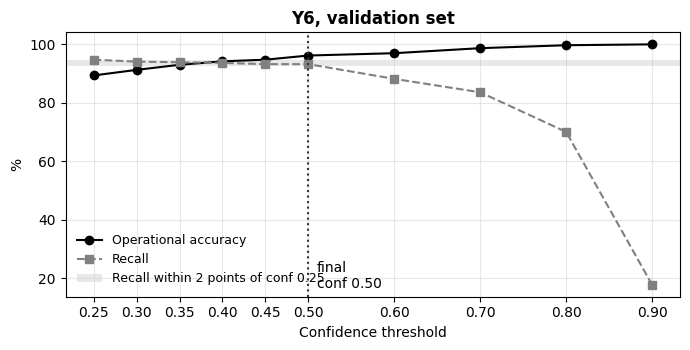

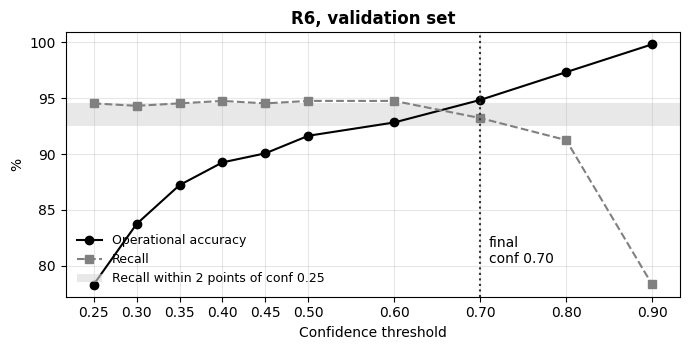

In [9]:
import matplotlib.pyplot as plt

for run_id in ["Y6", "R6"]:
    d = sweep[(sweep.Run == run_id) & (sweep.Split == "val")].sort_values("Conf")
    conf = d.Conf.values
    op = d["Op. acc. (mean)"].values * 100
    rec = d.Recall.values * 100

    # Final threshold: highest conf whose recall is within 2 points of recall at conf 0.25
    r0 = rec[0]
    final = conf[rec >= r0 - 2].max()

    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.plot(conf, op, "k-o", label="Operational accuracy")
    ax.plot(conf, rec, "--s", color="0.5", label="Recall")
    ax.axhspan(r0 - 2, r0, color="0.85", alpha=0.6, lw=0, label="Recall within 2 points of conf 0.25")
    ax.axvline(final, color="0.2", ls=":", lw=1.5)
    ax.text(final + 0.01, ax.get_ylim()[0] + 3, f"final\nconf {final:.2f}", fontsize=10)

    ax.set_xticks(conf)
    ax.set_xlabel("Confidence threshold")
    ax.set_ylabel("%")
    ax.set_title(f"{run_id}, validation set", fontweight="bold")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower left", fontsize=9, frameon=False)
    plt.tight_layout()
    plt.savefig(f"sweep_{run_id}.png", dpi=200)
    plt.show()